<a href="https://colab.research.google.com/github/TaegeunSONG/knu/blob/main/%EA%B3%A0%EC%9A%B4%EA%B3%A0%EB%93%B1%ED%95%99%EA%B5%90_%ED%8A%B9%EA%B0%95.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [75]:
# 공유자전거 데이터 다운로드
!wget -q 'https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip' -O bike.zip
!unzip -o -q bike.zip

# 파일 확인
!ls

bike.zip  day.csv  hour.csv  Readme.txt  sample_data


In [76]:
# 한글 폰트 설치
!apt-get -qq update
!apt-get -qq install fonts-nanum

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 폰트 캐시 갱신
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')

# Matplotlib 한글 폰트 설정
plt.rcParams['font.family'] = 'NanumGothic'

# 음수 기호 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)


# 라이브러리 불러오기

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


# 데이터 불러오기

In [78]:
df = pd.read_csv("hour.csv")

print(df.shape)
df.head()

(17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


# 데이터 내용 확인

In [79]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [80]:
df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [81]:
columns_korean = {
    "dteday": "날짜",
    "season": "계절",
    "yr": "연도",
    "mnth": "월",
    "hr": "시간",
    "holiday": "공휴일 여부",
    "weekday": "요일",
    "workingday": "근무일 여부",
    "weathersit": "날씨 상태",
    "temp": "기온",
    "atemp": "체감온도",
    "hum": "습도",
    "windspeed": "풍속",
    "cnt": "전체 자전거 대여량"
}

for col, meaning in columns_korean.items():
    print(col, ":", meaning)

dteday : 날짜
season : 계절
yr : 연도
mnth : 월
hr : 시간
holiday : 공휴일 여부
weekday : 요일
workingday : 근무일 여부
weathersit : 날씨 상태
temp : 기온
atemp : 체감온도
hum : 습도
windspeed : 풍속
cnt : 전체 자전거 대여량


# 익숙한 단위로 바꿔봅시다

In [82]:
df["temp_C"] = df["temp"] * 47 - 8
df["atemp_C"] = df["atemp"] * 66 - 16
df["humidity_percent"] = df["hum"] * 100
df["windspeed_kmh"] = df["windspeed"] * 67

df[["dteday", "hr", "temp_C", "humidity_percent", "windspeed_kmh", "cnt"]].head()

,dteday,hr,temp_C,humidity_percent,windspeed_kmh,cnt
0,2011-01-01,0,3.28,81.0,0.0,16
1,2011-01-01,1,2.34,80.0,0.0,40
2,2011-01-01,2,2.34,80.0,0.0,32
3,2011-01-01,3,3.28,75.0,0.0,13
4,2011-01-01,4,3.28,75.0,0.0,1


# 날짜 데이터 만들기

In [83]:
df["datetime"] = pd.to_datetime(df["dteday"]) + pd.to_timedelta(df["hr"], unit="h")

df[["datetime", "cnt"]].head()

,datetime,cnt
0,2011-01-01 00:00:00,16
1,2011-01-01 01:00:00,40
2,2011-01-01 02:00:00,32
3,2011-01-01 03:00:00,13
4,2011-01-01 04:00:00,1


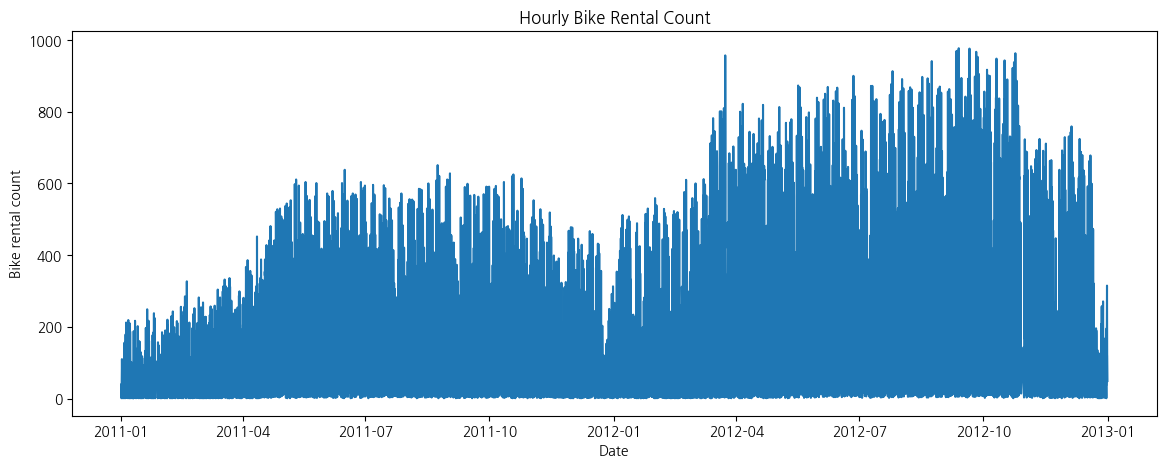

In [84]:
plt.figure(figsize=(14, 5))
plt.plot(df["datetime"], df["cnt"])
plt.xlabel("Date")
plt.ylabel("Bike rental count")
plt.title("Hourly Bike Rental Count")
plt.show()

# 시간에 따른 공유 자전거 이용량 보기

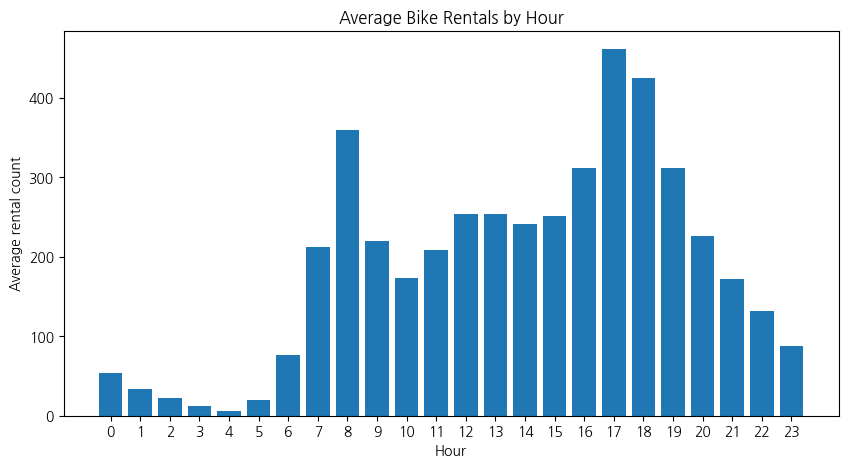

In [85]:
hourly_mean = df.groupby("hr")["cnt"].mean()

plt.figure(figsize=(10, 5))
plt.bar(hourly_mean.index, hourly_mean.values)
plt.xlabel("Hour")
plt.ylabel("Average rental count")
plt.title("Average Bike Rentals by Hour")
plt.xticks(range(0, 24))
plt.show()

# 계절에 따른 이용량

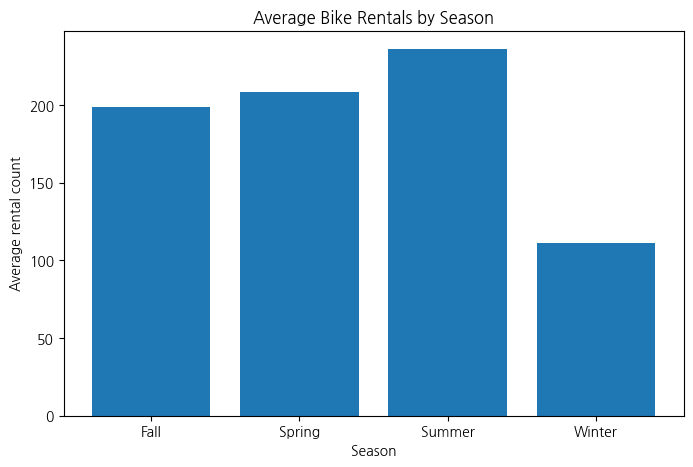

In [86]:
season_name = {
    1: "Winter",
    2: "Spring",
    3: "Summer",
    4: "Fall"
}

df["season_name"] = df["season"].map(season_name)

season_mean = df.groupby("season_name")["cnt"].mean()

plt.figure(figsize=(8, 5))
plt.bar(season_mean.index, season_mean.values)
plt.xlabel("Season")
plt.ylabel("Average rental count")
plt.title("Average Bike Rentals by Season")
plt.show()

# 날씨별 이용량

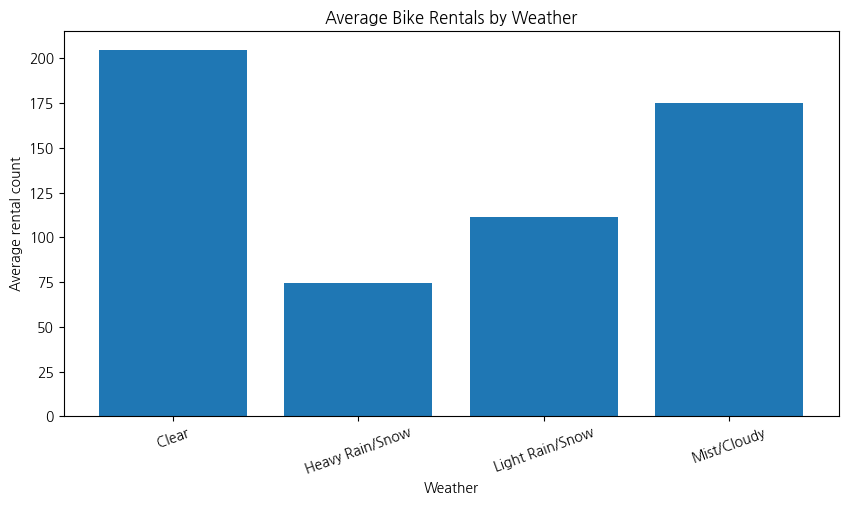

In [87]:
weather_name = {
    1: "Clear",
    2: "Mist/Cloudy",
    3: "Light Rain/Snow",
    4: "Heavy Rain/Snow"
}

df["weather_name"] = df["weathersit"].map(weather_name)

weather_mean = df.groupby("weather_name")["cnt"].mean()

plt.figure(figsize=(10, 5))
plt.bar(weather_mean.index, weather_mean.values)
plt.xlabel("Weather")
plt.ylabel("Average rental count")
plt.title("Average Bike Rentals by Weather")
plt.xticks(rotation=20)
plt.show()

# 기온별 이용량

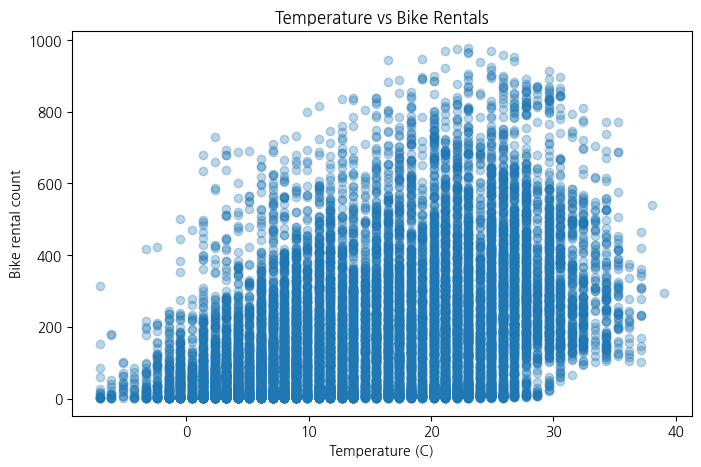

In [88]:
plt.figure(figsize=(8, 5))
plt.scatter(df["temp_C"], df["cnt"], alpha=0.3)
plt.xlabel("Temperature (C)")
plt.ylabel("Bike rental count")
plt.title("Temperature vs Bike Rentals")
plt.show()

# AI 예측에 사용할 입력값과 정답 찾기

In [89]:
features = [
    "season",
    "yr",
    "mnth",
    "hr",
    "holiday",
    "weekday",
    "workingday",
    "weathersit",
    "temp_C",
    "atemp_C",
    "humidity_percent",
    "windspeed_kmh"
]

target = "cnt"

X = df[features]
y = df[target]

X.head()

,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp_C,atemp_C,humidity_percent,windspeed_kmh
0,1,0,1,0,0,6,0,1,3.28,3.0014,81.0,0.0
1,1,0,1,1,0,6,0,1,2.34,1.9982,80.0,0.0
2,1,0,1,2,0,6,0,1,2.34,1.9982,80.0,0.0
3,1,0,1,3,0,6,0,1,3.28,3.0014,75.0,0.0
4,1,0,1,4,0,6,0,1,3.28,3.0014,75.0,0.0


# 앞에 80% 는 과거 데이터, 뒤에 20%를 예측해보기

## 데이터 분할 및 정규화

In [90]:

# 재현 가능하도록 랜덤 seed 고정
np.random.seed(42)
tf.random.set_seed(42)

# 딥러닝과 선형회귀는 입력값 크기 차이에 민감하므로 표준화
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("학습 데이터 개수:", len(X_train))
print("테스트 데이터 개수:", len(X_test))

학습 데이터 개수: 13903
테스트 데이터 개수: 3476


## 선형회기 모델

In [91]:
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)

linear_pred = linear_model.predict(X_test_scaled)

# 대여량은 음수가 될 수 없으므로 0보다 작은 예측값은 0으로 보정
linear_pred = np.maximum(linear_pred, 0)

linear_mae = mean_absolute_error(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))
linear_r2 = r2_score(y_test, linear_pred)

print("선형회귀 결과")
print("MAE:", linear_mae)
print("RMSE:", linear_rmse)
print("R2:", linear_r2)

선형회귀 결과
MAE: 138.28890427619615
RMSE: 183.27756827916275
R2: 0.30902672447583124


## Random Forest model

In [92]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_pred = np.maximum(rf_pred, 0)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("랜덤포레스트 결과")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R2:", rf_r2)

랜덤포레스트 결과
MAE: 45.77596584828524
RMSE: 70.3830120542497
R2: 0.898099029583231


# 딥러닝

In [93]:
deep_model = Sequential([
    Dense(128, activation="relu", input_shape=(X_train_scaled.shape[1],)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1)
])


# deep_model = Sequential([
#     Dense(64, activation="relu", input_shape=(X_train_scaled.shape[1],)),
#     Dense(32, activation="relu"),
#     Dense(1)
# ])


deep_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = deep_model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


348/348 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 16699.7168 - mae: 92.8815 - val_loss: 30634.0859 - val_mae: 140.1982
Epoch 2/100
348/348 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 9694.0000 - mae: 68.3275 - val_loss: 21306.6387 - val_mae: 106.8866
Epoch 3/100
348/348 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 7236.5210 - mae: 56.0935 - val_loss: 18172.5234 - val_mae: 95.2581
Epoch 4/100
348/348 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 6238.5903 - mae: 51.0854 - val_loss: 16247.4766 - val_mae: 90.7855
Epoch 5/100
348/348 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 4960.0801 - mae: 45.5106 - val_loss: 13101.2168 - val_mae: 80.7592
Epoch 6/100
348/348 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 3663.0620 - mae: 39.7452 - val_loss: 10432.3359 - val_mae: 70.8181
Epoch 7/100
348/348 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 2822.0215 - mae: 35.1714 - val_loss: 9007.8184 - val_mae: 65.4674
Epoch 8/100
348/348 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 2346.8613 - mae: 32.1537 - val_loss: 8233.5479 - val_

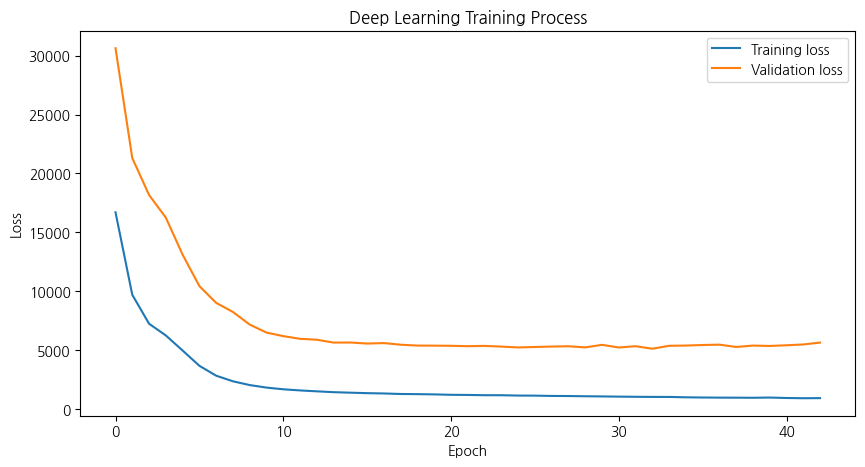

In [94]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Deep Learning Training Process")
plt.legend()
plt.show()

In [95]:
deep_pred = deep_model.predict(X_test_scaled).flatten()
deep_pred = np.maximum(deep_pred, 0)

deep_mae = mean_absolute_error(y_test, deep_pred)
deep_rmse = np.sqrt(mean_squared_error(y_test, deep_pred))
deep_r2 = r2_score(y_test, deep_pred)

print("딥러닝 결과")
print("MAE:", deep_mae)
print("RMSE:", deep_rmse)
print("R2:", deep_r2)


109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
딥러닝 결과
MAE: 58.04734420776367
RMSE: 89.79087574574324
R2: 0.8341531753540039


In [96]:
def evaluate_model(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, r2

linear_mae, linear_rmse, linear_r2 = evaluate_model(y_test, linear_pred)
rf_mae, rf_rmse, rf_r2 = evaluate_model(y_test, rf_pred)
deep_mae, deep_rmse, deep_r2 = evaluate_model(y_test, deep_pred)

comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest", "Simple Deep Learning"],
    "MAE": [linear_mae, rf_mae, deep_mae],
    "RMSE": [linear_rmse, rf_rmse, deep_rmse],
    "R2": [linear_r2, rf_r2, deep_r2]
})

comparison

,Model,MAE,RMSE,R2
0,Linear Regression,138.288904,183.277568,0.309027
1,Random Forest,45.775966,70.383012,0.898099
2,Simple Deep Learning,58.047344,89.790876,0.834153


# 성능비교

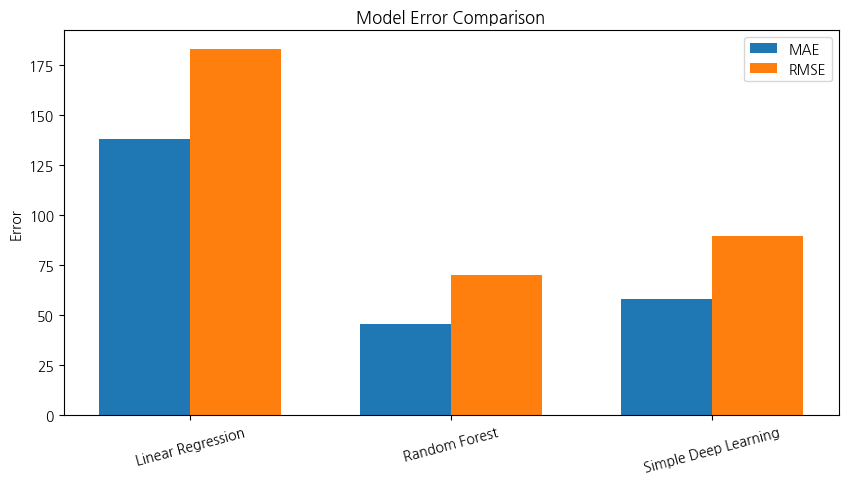

In [97]:
plt.figure(figsize=(10, 5))

x = np.arange(len(comparison["Model"]))
width = 0.35

plt.bar(x - width/2, comparison["MAE"], width, label="MAE")
plt.bar(x + width/2, comparison["RMSE"], width, label="RMSE")

plt.xticks(x, comparison["Model"], rotation=15)
plt.ylabel("Error")
plt.title("Model Error Comparison")
plt.legend()
plt.show()

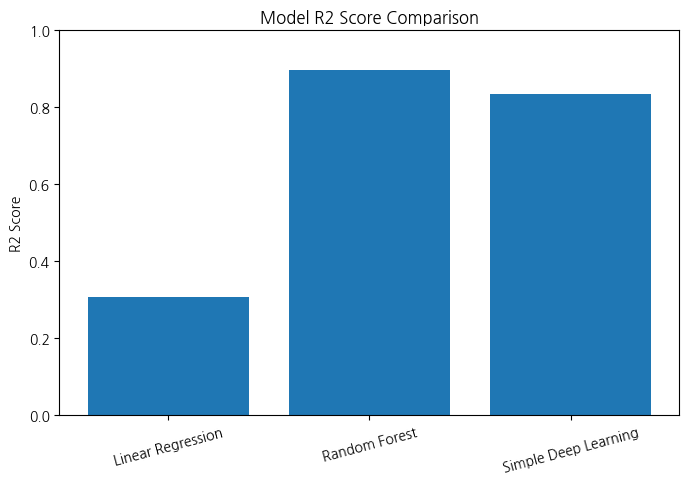

In [98]:
plt.figure(figsize=(8, 5))

plt.bar(comparison["Model"], comparison["R2"])
plt.ylabel("R2 Score")
plt.title("Model R2 Score Comparison")
plt.xticks(rotation=15)
plt.ylim(0, 1)

plt.show()

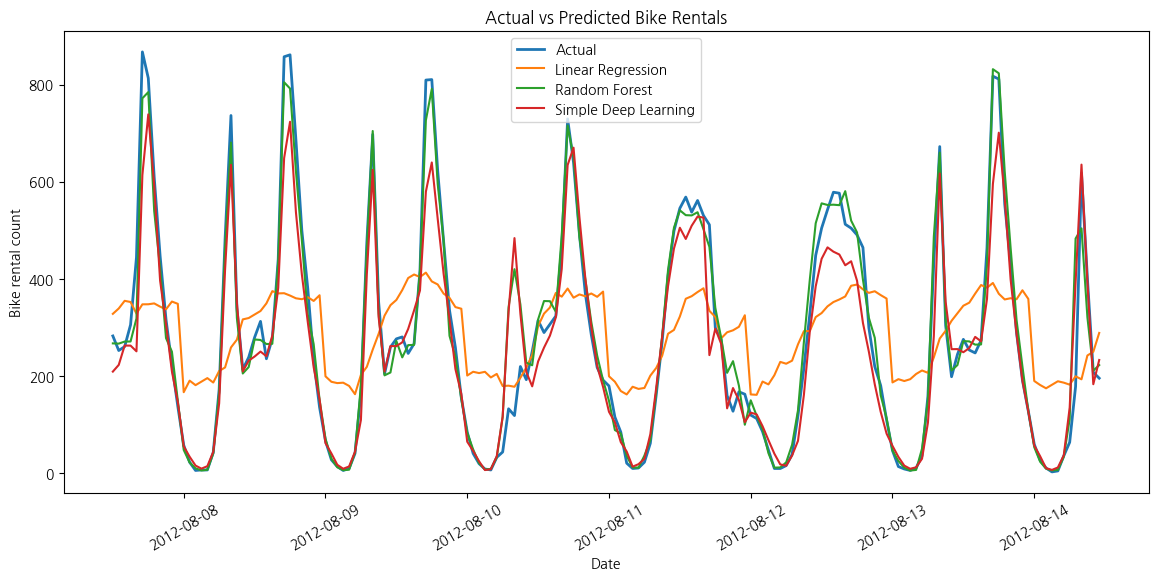

In [99]:
compare_df = pd.DataFrame({
    "datetime": df["datetime"].iloc[split_index:].values,
    "Actual": y_test.values,
    "Linear Regression": linear_pred,
    "Random Forest": rf_pred,
    "Simple Deep Learning": deep_pred
})

# 테스트 데이터 중 앞의 168시간만 보기
sample = compare_df.iloc[:168]

plt.figure(figsize=(14, 6))

plt.plot(sample["datetime"], sample["Actual"], label="Actual", linewidth=2)
plt.plot(sample["datetime"], sample["Linear Regression"], label="Linear Regression")
plt.plot(sample["datetime"], sample["Random Forest"], label="Random Forest")
plt.plot(sample["datetime"], sample["Simple Deep Learning"], label="Simple Deep Learning")

plt.xlabel("Date")
plt.ylabel("Bike rental count")
plt.title("Actual vs Predicted Bike Rentals")
plt.legend()
plt.xticks(rotation=30)
plt.show()

# Random Forest -> feature importance

In [100]:
importance = pd.DataFrame({
    "feature": features,
    "importance": rf_model.feature_importances_
}).sort_values("importance", ascending=False)

importance

,feature,importance
3,hr,0.610892
9,atemp_C,0.089001
8,temp_C,0.077972
1,yr,0.069239
6,workingday,0.057835
10,humidity_percent,0.026068
7,weathersit,0.018937
0,season,0.013251
2,mnth,0.012961
5,weekday,0.012140


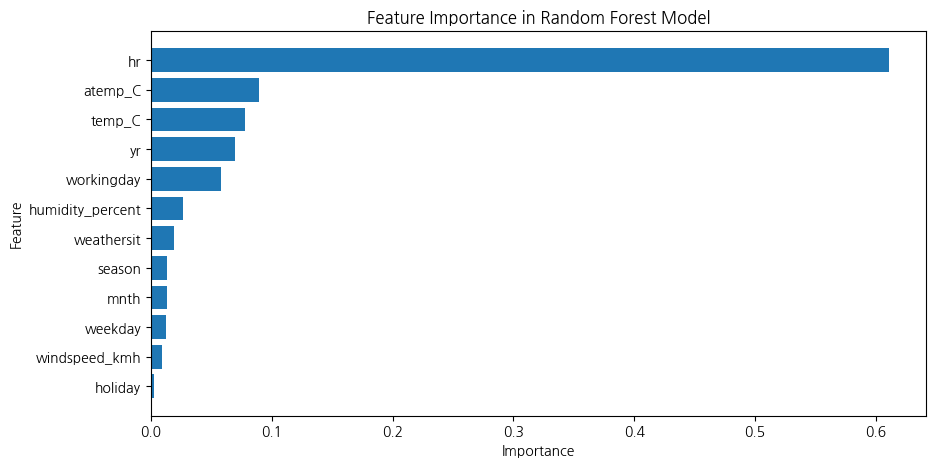

In [101]:
plt.figure(figsize=(10, 5))
plt.barh(importance["feature"], importance["importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance in Random Forest Model")
plt.gca().invert_yaxis()
plt.show()

In [102]:
# 예시 조건
# 여름, 2012년, 7월, 오후 6시, 공휴일 아님, 금요일, 근무일, 맑음, 기온 28도, 체감온도 30도, 습도 60%, 풍속 10km/h

new_data = pd.DataFrame({
    "season": [3],              # 1 겨울, 2 봄, 3 여름, 4 가을
    "yr": [1],                  # 0: 2011, 1: 2012
    "mnth": [7],                # 월
    "hr": [18],                 # 시간
    "holiday": [0],             # 공휴일 여부
    "weekday": [5],             # 요일
    "workingday": [1],          # 근무일 여부
    "weathersit": [1],          # 1 맑음, 2 흐림, 3 약한 비/눈, 4 강한 비/눈
    "temp_C": [28],
    "atemp_C": [30],
    "humidity_percent": [60],
    "windspeed_kmh": [10]
})

predicted_count = rf_model.predict(new_data)

print("예상 공유자전거 이용량:", int(predicted_count[0]), "대")

예상 공유자전거 이용량: 637 대


In [103]:
def predict_bike_rental(
    season=3,
    month=7,
    hour=18,
    weekday=5,
    workingday=1,
    weather=1,
    temp_C=28,
    humidity=60,
    windspeed=10
):
    input_data = pd.DataFrame({
        "season": [season],
        "yr": [1],
        "mnth": [month],
        "hr": [hour],
        "holiday": [0],
        "weekday": [weekday],
        "workingday": [workingday],
        "weathersit": [weather],
        "temp_C": [temp_C],
        "atemp_C": [temp_C + 2],
        "humidity_percent": [humidity],
        "windspeed_kmh": [windspeed]
    })

    pred = rf_model.predict(input_data)[0]
    return int(pred)

In [104]:
predict_bike_rental(
    season=3,
    month=7,
    hour=18,
    weekday=5,
    workingday=1,
    weather=1,
    temp_C=28,
    humidity=60,
    windspeed=10
)

637

In [105]:
scenarios = pd.DataFrame({
    "scenario": [
        "맑은 여름 평일 오후 6시",
        "비 오는 여름 평일 오후 6시",
        "맑은 겨울 평일 오전 8시",
        "맑은 가을 주말 오후 2시"
    ],
    "season": [3, 3, 1, 4],
    "month": [7, 7, 1, 10],
    "hour": [18, 18, 8, 14],
    "weekday": [5, 5, 2, 6],
    "workingday": [1, 1, 1, 0],
    "weather": [1, 3, 1, 1],
    "temp_C": [28, 28, 2, 20],
    "humidity": [60, 85, 40, 50],
    "windspeed": [10, 20, 8, 7]
})

predictions = []

for i in range(len(scenarios)):
    row = scenarios.iloc[i]
    pred = predict_bike_rental(
        season=row["season"],
        month=row["month"],
        hour=row["hour"],
        weekday=row["weekday"],
        workingday=row["workingday"],
        weather=row["weather"],
        temp_C=row["temp_C"],
        humidity=row["humidity"],
        windspeed=row["windspeed"]
    )
    predictions.append(pred)

scenarios["predicted_rental_count"] = predictions
scenarios

,scenario,season,month,hour,weekday,workingday,weather,temp_C,humidity,windspeed,predicted_rental_count
0,맑은 여름 평일 오후 6시,3,7,18,5,1,1,28,60,10,637
1,비 오는 여름 평일 오후 6시,3,7,18,5,1,3,28,85,20,538
2,맑은 겨울 평일 오전 8시,1,1,8,2,1,1,2,40,8,494
3,맑은 가을 주말 오후 2시,4,10,14,6,0,1,20,50,7,592


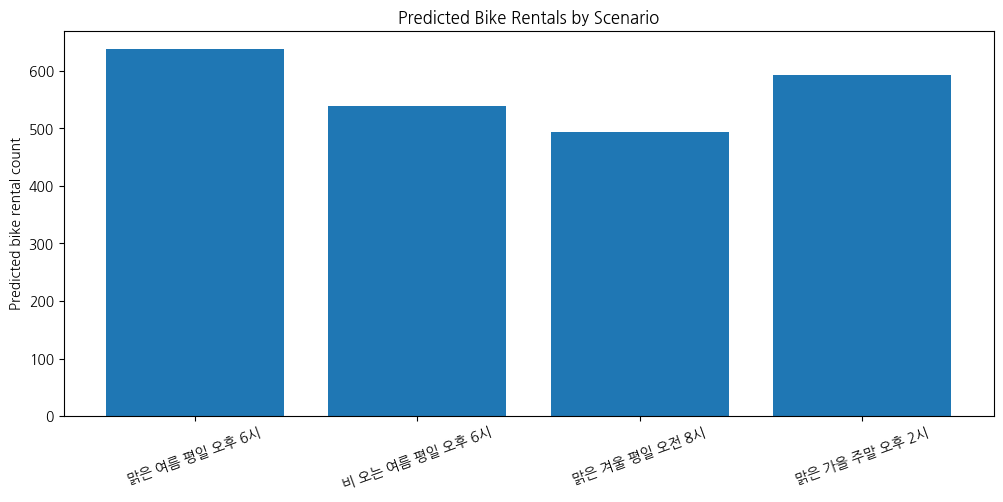

In [106]:
plt.figure(figsize=(12, 5))
plt.bar(scenarios["scenario"], scenarios["predicted_rental_count"])
plt.ylabel("Predicted bike rental count")
plt.title("Predicted Bike Rentals by Scenario")
plt.xticks(rotation=20)
plt.show()